# Can we predict the type of a furniture item from its specifications?

**Direction 21 - Furniture · Task type: classification**
Team: Sultanbek Zhumagaliev, Tamerlan Yessimov

**Question.** Can the type of a furniture item (sofa, armchair, chair, bed, wardrobe, chest of drawers, desk, coffee table, TV stand) be predicted from its structured specifications: width, depth, height, materials, colour and price?

**Why it matters.** Marketplaces receive thousands of listings. Sellers fill in the dimensions, but they often put the item in the wrong category. A model that predicts the type from the specs can flag listings whose category disagrees with their numbers. The analysis also shows which specifications separate similar types (wardrobe vs chest of drawers, chair vs armchair) and prepares the ground for recognising furniture type from product photos.

### Contents
1. Question, data and data ethics
2. Data preparation and exploration (cleaning, leakage check, exploration)
3. Modelling workflow (split, pipeline, baseline, three Week 3-4 models, cross-validation)
4. Results and error analysis (metric, fair comparison, confusion matrix, where the model fails)
5. Conclusions and limitations
6. Contributions and AI tools

## 1. Question, data and data ethics

### 1.1 Source and collection
* **Source:** the online store [mebel.kz](https://mebel.kz/) (TOO "Mebel Group KZ", Almaty). The full data card is in `DATA_CARD.md`.
* **How we collected it:** `scraper/collect_mebel.py`:
  1. reads the public sitemap `https://mebel.kz/sitemap.almaty.xml`;
  2. keeps the product URLs whose address looks like one of the nine furniture types;
  3. samples at most 700 per type (seed 42);
  4. downloads each product page;
  5. stores the schema.org JSON-LD product block (name, category, price), the breadcrumbs, the overall size block and the whole specification table in `data/raw/mebel_raw.jsonl`.

  `scraper/build_dataset.py` then turns these raw records into `data/processed/furniture.csv`.
* **One row = one product listing** (one model in one colour/fabric) on mebel.kz.
* **Target:** the store's own category for the product, mapped to our nine types with an explicit dictionary (`CATEGORY_TO_TYPE` in `build_dataset.py`).

### 1.2 How we checked the source
* We read `robots.txt`. It allows `/product/` pages, and we did not request anything it disallows (`/order`, `/terms`, `/data`, ...).
* We compared several scraped rows by hand with the live pages (sizes, price, materials). The automatic checks are in section 2.1.
* The JSON-LD price matches the price shown on the page. The sizes come from the "Размеры" block that customers see.
* While checking, we found that the first version of the size parser missed two page layouts. We fixed it and downloaded the affected pages again (logged in `collection_log.json`).

### 1.3 Data ethics
* **Only public catalogue data.** No accounts or logins were used, and there are no reviews, customer names or other personal data. The shop publishes these prices and specs for anyone to read.
* **Polite collection.** At most 2 connections at a time, at least 0.7 s between requests, and a User-Agent that says this is a student research scraper. Each page was downloaded once and saved as structured JSON, so the analysis never touches the website again.
* **Purpose.** Education and research only. The data is not re-published as a product.

### 1.4 What is missing compared to the task description
The task lists **weight** as a feature. mebel.kz does not publish product weight on its product pages: we checked the page text and the embedded page data for every type. So weight is **not** in our data. This is listed again in the limitations.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
TYPES = ["sofa", "armchair", "chair", "bed", "wardrobe", "chest_of_drawers", "desk", "coffee_table", "tv_stand"]

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| numpy", np.__version__)

pandas 3.0.6 | scikit-learn 1.9.1 | numpy 2.5.3


In [2]:
# When and how much did we collect?
log = json.loads(Path("data/raw/collection_log.json").read_text())
raw = [json.loads(line) for line in open("data/raw/mebel_raw.jsonl")]
dates = sorted(r["scraped_at"] for r in raw)
print("Source:                       ", log["source"])
print("Product URLs in sitemap:      ", log["products_in_sitemap"])
print("Candidate URLs (9 types):     ", log["candidate_urls"])
print("After cap of", log["cap_per_type"], "per type:     ", log["candidate_urls_after_cap"])
print("Raw records saved:            ", len(raw))
print("Collected between (UTC):      ", dates[0], "and", dates[-1])
print("Politeness:                   ", log["parallel_connections"], "connections,", log["min_seconds_between_requests"], "s between requests")
print("Re-downloads after parser fix:", log.get("refetches"))

Source:                        https://mebel.kz/
Product URLs in sitemap:       9019
Candidate URLs (9 types):      6000
After cap of 700 per type:      4630
Raw records saved:             4630
Collected between (UTC):       2026-10-07T11:46:39+00:00 and 2026-10-07T13:16:58+00:00
Politeness:                    2 connections, 0.7 s between requests
Re-downloads after parser fix: [{'finished_utc': '2026-10-07T13:16:58+00:00', 'pages_refetched': 520, 'now_complete': 353}]


In [3]:
# One raw record, as it was saved (long text shortened)
example = dict(raw[len(raw) // 2])
example["product"] = {k: (v[:80] + "...") if isinstance(v, str) and len(v) > 80 else v for k, v in example["product"].items()}
print(json.dumps(example, ensure_ascii=False, indent=1)[:2500])

{
 "url": "https://mebel.kz/product/krovat-nordik-160-wood-grey",
 "scraped_at": "2026-10-07T12:28:04+00:00",
 "product": {
  "name": "Кровать Нордик 160 Натуральный Серый",
  "sku": "190469",
  "category": "Кровати",
  "color": "Бежевый",
  "description": "Кровать Нордик 160 Натуральный Серый напрямую от производителя в интернет-магази...",
  "price": "183670.00",
  "currency": "KZT",
  "availability": "https://schema.org/InStock"
 },
 "breadcrumbs": [
  "🏠 Интернет-магазин mebel.kz",
  "🛏️ Кровати и матрасы",
  "🛏️ Кровати",
  "🛏️ Кровать Нордик 160 Натуральный Серый"
 ],
 "dimensions": {
  "Длина": "203",
  "Ширина": "165",
  "Высота": "98"
 },
 "specs": {
  "Материал корпуса": "ЛДСП 16 мм",
  "Материал изголовья": "ЛДСП 16 мм",
  "Материал ножек (опор)": "деревянные (сращенный массив)",
  "Подъемный механизм": "без механизма",
  "Наличие ящика для белья": "без ящика для белья",
  "Опоры": "Нордик 1 Древесный (Опора массив ВС 001 древесный 250мм)",
  "Основание кровати": "ортопедиче

In [4]:
df = pd.read_csv("data/processed/furniture.csv")
print(df.shape)
df.head()

(3961, 14)


,url,scraped_at,sku,name,site_category,series,furniture_type,width_cm,depth_cm,height_cm,price_kzt,materials,main_color,n_spec_fields
0,https://mebel.kz/product/detskaya-krovat-andji...,2026-10-07,264693,Детская кровать Анджи 80 Вельвет Голубой,Детские кровати,Анджи,bed,172.0,96.0,64.0,290860.0,chipboard|fabric|mdf|plywood|solid_wood,light_blue,19
1,https://mebel.kz/product/detskaya-krovat-andji...,2026-10-07,264632,Детская кровать Анджи 80 Вельвет Мятный,Детские кровати,Анджи,bed,172.0,96.0,64.0,290860.0,chipboard|fabric|mdf|plywood|solid_wood,green,19
2,https://mebel.kz/product/detskaya-krovat-andji...,2026-10-07,264689,Детская кровать Анджи 80 Вельвет Оливковый,Детские кровати,Анджи,bed,172.0,96.0,64.0,290860.0,chipboard|fabric|mdf|plywood|solid_wood,olive,19
3,https://mebel.kz/product/detskaya-krovat-andji...,2026-10-07,264665,Детская кровать Анджи 80 Вельвет Красный,Детские кровати,Анджи,bed,172.0,96.0,64.0,290860.0,chipboard|fabric|mdf|plywood|solid_wood,red,19
4,https://mebel.kz/product/detskaya-krovat-andji...,2026-10-07,268013,Детская кровать Анджи 80 Вельвет Бежевый,Детские кровати,Анджи,bed,172.0,96.0,64.0,290860.0,chipboard|fabric|mdf|plywood|solid_wood,beige,19


### 1.5 Fields of the processed table

| Column | Meaning | Used as input? |
|---|---|---|
| `url`, `sku`, `name` | product address, store code, product name | **no** - identifiers; the name contains the type ("Кровать ...") |
| `site_category` | the store's category, e.g. "Шкафы распашные" | **no** - this *is* the answer |
| `furniture_type` | our target, one of the nine types | target |
| `series` | product series (e.g. "Леванте"); colour variants share it | **no** - used only to group rows in cross-validation |
| `width_cm`, `depth_cm`, `height_cm` | outer size; the site writes "Длина x Ширина x Высота", which we read as width x depth x height | yes |
| `price_kzt` | price in tenge on the collection date | yes |
| `materials` | material words found in all "Материал ..." and "Каркас" fields, normalised to tokens like `chipboard`, `mdf`, `fabric` | yes |
| `main_color` | first colour in the "Цвет" field, translated | yes |
| `n_spec_fields` | how many spec fields the page has | **no** - kept to show a leak (2.3) |
| `scraped_at` | collection date | no |

## 2. Data preparation and exploration

### 2.1 Cleaning
`build_dataset.py` has already dropped two kinds of rows: products whose category is not one of our nine types (sofa modules, office chairs, nightstands, ...), and products without all three sizes or without a price. Here we check that the remaining values make physical sense.

In [5]:
num_cols = ["width_cm", "depth_cm", "height_cm", "price_kzt"]
df[num_cols].describe().round(1)

,width_cm,depth_cm,height_cm,price_kzt
count,3961.0,3961.0,3961.0,3961.0
mean,139.9,78.6,103.4,293156.4
std,66.0,48.7,55.2,230622.5
min,25.0,23.0,19.9,30550.0
25%,85.0,46.0,76.0,153050.0
50%,137.0,55.0,85.0,229610.0
75%,203.0,96.0,102.0,375070.0
max,421.0,320.0,300.0,2284860.0


In [6]:
n0 = len(df)
steps = {}

# 1. Impossible or broken sizes: below 10 cm or above 5 m on any side
sizes = df[["width_cm", "depth_cm", "height_cm"]]
bad_size = (sizes < 10).any(axis=1) | (sizes > 500).any(axis=1)
steps["size < 10 cm or > 500 cm"] = int(bad_size.sum())
df = df[~bad_size]

# 2. Prices that cannot be a real furniture price (below 5,000 tenge)
bad_price = df["price_kzt"] < 5_000
steps["price < 5,000 KZT"] = int(bad_price.sum())
df = df[~bad_price]

# 3. Exact duplicates of the same URL (should be none)
dup = df.duplicated("url")
steps["duplicate URL"] = int(dup.sum())
df = df[~dup]

# 4. Missing colour gets its own value instead of dropping the row
steps["missing colour -> 'unknown' (kept)"] = int(df["main_color"].isna().sum())
df["main_color"] = df["main_color"].fillna("unknown")
df["materials"] = df["materials"].fillna("")
steps["no material found -> all material flags 0 (kept)"] = int((df["materials"] == "").sum())

df = df.reset_index(drop=True)
print(pd.Series(steps, name="rows affected").to_string())
print(f"\nrows: {n0} -> {len(df)}")

size < 10 cm or > 500 cm                            0
price < 5,000 KZT                                   0
duplicate URL                                       0
missing colour -> 'unknown' (kept)                  5
no material found -> all material flags 0 (kept)    7

rows: 3961 -> 3961


In [7]:
# Same specs and same type in different listings = colour variants of one model.
# Same specs but a *different* type would be label noise. How common is each?
feat = ["width_cm", "depth_cm", "height_cm", "price_kzt", "materials"]
same_specs = df.groupby(feat)["furniture_type"].agg(["size", "nunique"])
print("rows whose specs (size, price, materials) also appear in another row:", int(same_specs.loc[same_specs["size"] > 1, "size"].sum()))
print("spec combinations that carry more than one type label:", int((same_specs["nunique"] > 1).sum()))
per_series = df.groupby("series").size()
print(f"series: {len(per_series)}, listings per series - median {per_series.median():.0f}, max {per_series.max()}")

rows whose specs (size, price, materials) also appear in another row: 3162
spec combinations that carry more than one type label: 0
series: 512, listings per series - median 3, max 178


### 2.2 Class balance

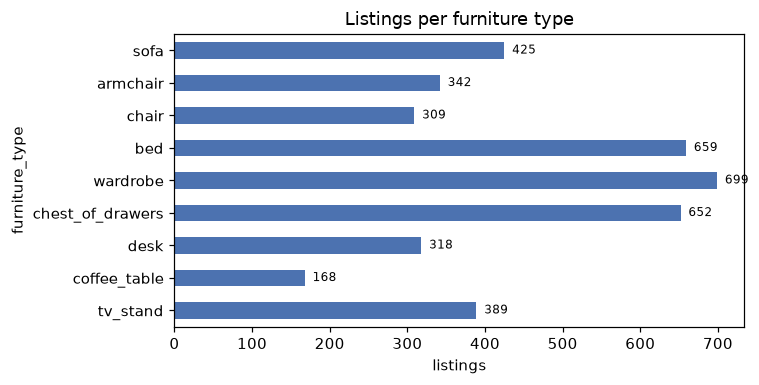

furniture_type
sofa                0.107
armchair            0.086
chair               0.078
bed                 0.166
wardrobe            0.176
chest_of_drawers    0.165
desk                0.080
coffee_table        0.042
tv_stand            0.098


In [8]:
counts = df["furniture_type"].value_counts().reindex(TYPES)
ax = counts.plot.barh(color="#4C72B0", figsize=(7, 3.6))
ax.invert_yaxis(); ax.set_xlabel("listings"); ax.set_title("Listings per furniture type")
for i, v in enumerate(counts):
    ax.text(v + 10, i, str(v), va="center", fontsize=8)
plt.tight_layout(); plt.show()
print((counts / counts.sum()).round(3).to_string())

The classes are **imbalanced**. Plain accuracy would reward a model that is good at the large classes and ignores the small ones, so our main metric is **macro-F1**: the F1 score of every class averaged with equal weight. A model can only score high if it recognises coffee tables and desks as well as wardrobes and beds.

### 2.3 Leakage check
Leakage means an input that would not be available in the real use case, or that is the answer in disguise. Our use case: a seller has typed in the size, price, materials and colour, and we want to check the category they chose. We checked three possible leaks.

**(a) Text fields contain the answer.** The product name usually starts with the type word ("Кровать ...", "Комод ..."), and the URL, description, breadcrumbs and `site_category` say it directly.

In [9]:
type_words = {"sofa": "диван", "armchair": "кресл", "chair": "стул", "bed": "кроват", "wardrobe": "шкаф",
              "chest_of_drawers": "комод", "desk": "стол", "coffee_table": "стол", "tv_stand": "тумб"}
hit = df.apply(lambda r: type_words[r["furniture_type"]] in str(r["name"]).lower(), axis=1)
print(f"Product names that contain their own type word: {hit.mean():.1%}")
print(hit.groupby(df["furniture_type"]).mean().reindex(TYPES).round(3).to_string())
print("-> name, url, description, breadcrumbs and site_category are NOT used as inputs.")

Product names that contain their own type word: 92.9%
furniture_type
sofa                1.000
armchair            1.000
chair               0.994
bed                 1.000
wardrobe            1.000
chest_of_drawers    0.598
desk                0.947
coffee_table        1.000
tv_stand            1.000
-> name, url, description, breadcrumbs and site_category are NOT used as inputs.


**(b) Which spec fields a page has gives the type away.** Only beds have "Спальное место"/"Основание кровати", only sofas have "Механизм трансформации", and only wardrobes have "Дверная система". If we turned every spec field into an input, the model would only learn which fields are present. Below we prove it: a small decision tree that sees *only* which spec fields are present (no numbers at all) already reaches a macro-F1 far above the baseline. That score says nothing about our question. So we only use the fields the question allows: sizes, price, colour, and material *values* pooled over all material fields, so that a field name such as "Материал изголовья" (headboard material) cannot leak.

In [10]:
keys_by_url = {r["url"]: set(r["specs"]) for r in raw}
key_counts = pd.Series([k for u in df["url"] for k in keys_by_url[u]]).value_counts()
common_keys = key_counts[key_counts >= 30].index
X_keys = pd.DataFrame([[k in keys_by_url[u] for k in common_keys] for u in df["url"]], columns=common_keys, dtype=int)

group_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
leak = cross_validate(DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE), X_keys, df["furniture_type"],
                      groups=df["series"], cv=group_cv, scoring="f1_macro")
print(f"{len(common_keys)} 'page has this spec field' flags only -> macro-F1 = {leak['test_score'].mean():.3f}")

tree_keys = DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE).fit(X_keys, df["furniture_type"])
print("Fields the tree uses most:", pd.Series(tree_keys.feature_importances_, index=common_keys).nlargest(6).round(3).to_dict())

leak_n = cross_validate(DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE), df[["n_spec_fields"]], df["furniture_type"],
                        groups=df["series"], cv=group_cv, scoring="f1_macro")
print(f"Only the NUMBER of spec fields -> macro-F1 = {leak_n['test_score'].mean():.3f}  (also excluded)")

63 'page has this spec field' flags only -> macro-F1 = 0.863
Fields the tree uses most: {'Основание кровати': 0.22, 'Дверная система': 0.206, 'Материал столешницы': 0.164, 'Материал корпуса': 0.137, 'Складной': 0.106, 'Расположение': 0.097}


Only the NUMBER of spec fields -> macro-F1 = 0.179  (also excluded)
